# Empirical Orthogonal Function (EOF) analysis

Empirical Orthogonal Functions (EOFs) decompose a space–time field into a set of fixed spatial patterns (the EOFs) multiplied by time series (the principal components, PCs):

$$ T'(x, y, t) = \sum_{k} \mathrm{PC}_k(t) \, \mathrm{EOF}_k(x, y) .$$

The EOFs are orthogonal in space and the PCs are uncorrelated in time. They are ordered so that the first mode explains the largest fraction of the variance of $T'$, the second mode explains the largest fraction of what is left, and so on. EOF analysis is the same as principal component analysis (PCA) applied to a geophysical field; the EOFs are the eigenvectors of the spatial covariance matrix of $T'$.

This recipe uses the [`eofs`](https://ajdawson.github.io/eofs/latest/) package to do an EOF analysis of monthly sea surface temperature (SST) anomalies in the tropical Pacific from the ACCESS-OM2 0.25° interannually forced (IAF) run, 1958–2018. The first EOF is the El Niño–Southern Oscillation (ENSO) pattern. We check this by comparing its principal component with the Niño 3.4 index computed from the same model output.

The steps are:
1. Load monthly SST and grid-cell area.
2. Remove the seasonal cycle and the linear trend to obtain SST anomalies.
3. Weight each grid cell by the square root of its area.
4. Compute the EOFs, PCs and the fraction of variance explained by each mode.
5. Compare the leading PC with the Niño 3.4 index.

#### Converting to MOM6

This notebook uses MOM5 output (ACCESS-OM2). To use MOM6 output (e.g. ACCESS-OM3) change the following names:

| MOM5 | MOM6 |
|---|---|
| `xt_ocean` | `xh` |
| `yt_ocean` | `yh` |
| `sst` | `tos` |
| `area_t` | `areacello` |

The EOF analysis itself does not depend on the model.

In [1]:
import intake
import numpy as np
import xarray as xr
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cft
import cmocean.cm as cmo
from eofs.xarray import Eof

from dask.distributed import Client

In [2]:
client = Client(threads_per_worker=1)
client

Connection method: Cluster object,Cluster type: distributed.LocalCluster
Dashboard: http://127.0.0.1:8787/status,
Dashboard: http://127.0.0.1:8787/status,Workers: 14
Total threads: 14,Total memory: 56.00 GiB
Status: running,Using processes: True
Comm: tcp://127.0.0.1:32985,Workers: 0
Dashboard: http://127.0.0.1:8787/status,Total threads: 0
Started: Just now,Total memory: 0 B
Comm: tcp://127.0.0.1:39745,Total threads: 1
Dashboard: http://127.0.0.1:33459/status,Memory: 4.00 GiB
Nanny: tcp://127.0.0.1:40269,


## Load the data

We use the ACCESS-NRI intake catalog and the 0.25° IAF experiment, which is forced with the JRA55-do atmospheric reanalysis from 1958 to 2018. Because the forcing is the observed atmosphere, the model's ENSO events should line up in time with the observed ones.

In [3]:
catalog = intake.cat.access_nri

experiment = '025deg_jra55_iaf_omip2_cycle6'

start_time, end_time = '1958-01-01', '2018-12-31'

Select the tropical Pacific, 20°S–20°N and 120°E–80°W. ACCESS-OM2 longitudes run from −280° to 80°, so 120°E–80°W is −240° to −80°. After selecting the region we convert longitudes to the 0°–360° range (120° to 280°), which is easier to read and plot across the dateline.

In [4]:
lat_range = slice(-20, 20)
lon_range = slice(-240, -80)

def to_0_360(da):
    return da.assign_coords(xt_ocean=da.xt_ocean % 360)

In [5]:
sst = catalog[experiment].search(
    variable='sst', frequency='1mon', variable_cell_methods='time: mean'
).to_dask(
    xarray_open_kwargs=dict(use_cftime=True, chunks={'yt_ocean': -1, 'xt_ocean': -1}),
    xarray_combine_by_coords_kwargs=dict(compat='override', data_vars='minimal', coords='minimal'),
)['sst']

sst = sst.sel(time=slice(start_time, end_time), yt_ocean=lat_range, xt_ocean=lon_range)
sst = to_0_360(sst)
sst

<xarray.DataArray 'sst' (time: 732, yt_ocean: 164, xt_ocean: 640)> Size: 307MB
dask.array<getitem, shape=(732, 164, 640), dtype=float32, chunksize=(1, 164, 640), chunktype=numpy.ndarray>
Coordinates:
  * time      (time) object 6kB 1958-01-14 12:00:00 ... 2018-12-14 12:00:00
  * yt_ocean  (yt_ocean) float64 1kB -19.96 -19.72 -19.49 ... 19.49 19.72 19.96
  * xt_ocean  (xt_ocean) float64 5kB 120.1 120.4 120.6 ... 279.4 279.6 279.9
Attributes:
    long_name:      Potential temperature
    units:          K
    valid_range:    [-10. 500.]
    cell_methods:   time: mean
    time_avg_info:  average_T1,average_T2,average_DT
    standard_name:  sea_surface_temperature

The SST output is in Kelvin; convert it to °C. (An anomaly is the same in both units, but °C is more familiar on plots.) Then load the data into memory: the tropical Pacific at 0.25° for 61 years is only a few hundred MB.

In [6]:
if sst.attrs.get('units', '').strip() in ('K', 'kelvin', 'Kelvin', 'degrees K'):
    sst = sst - 273.15
sst.attrs['units'] = '°C'

sst = sst.load()

In [7]:
# the grid doesn't change, so we only need one of the grid files
area_search = catalog[experiment].search(variable='area_t', frequency='fx')
area = area_search.search(path=area_search.df.path[0]).to_dask()['area_t']
area = to_0_360(area.sel(yt_ocean=lat_range, xt_ocean=lon_range)).load()

# land cells have no SST; give them zero area so they never contribute
area = area.where(sst.isel(time=0).notnull(), 0)

## SST anomalies

EOFs describe variability about the mean, so we first remove

1. the **seasonal cycle**, i.e. the mean for each calendar month; otherwise the first EOF would just be the annual cycle, and
2. the **linear trend** at each grid point; otherwise the warming over 1958–2018 would appear as one of the leading modes.

The trend is fitted by least squares against time in months.

In [8]:
climatology = sst.groupby('time.month').mean('time')
sst_anom = sst.groupby('time.month') - climatology

t = xr.DataArray(np.arange(sst_anom.sizes['time'], dtype=float), dims='time', coords={'time': sst_anom.time})
t = t - t.mean()
slope = (sst_anom * t).sum('time') / (t**2).sum()   # °C per month

sst_anom = sst_anom - sst_anom.mean('time') - slope * t
sst_anom = sst_anom.drop_vars('month')
sst_anom.attrs['units'] = '°C'

Here is the linear trend we removed, in °C per decade:

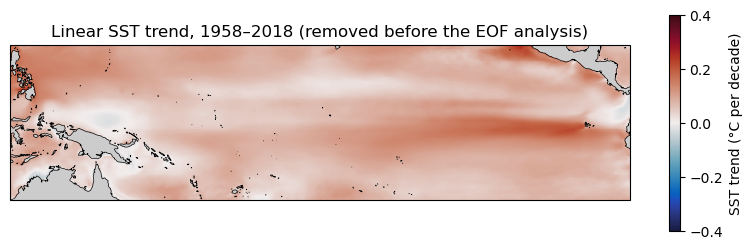

In [9]:
fig = plt.figure(figsize=(10, 3.5))
ax = plt.axes(projection=ccrs.PlateCarree(central_longitude=180))
(slope * 120).where(area > 0).plot(
    ax=ax, transform=ccrs.PlateCarree(), cmap=cmo.balance, vmin=-0.4, vmax=0.4,
    cbar_kwargs={'label': 'SST trend (°C per decade)', 'shrink': 0.8},
)
ax.add_feature(cft.LAND, color='0.8')
ax.coastlines(linewidth=0.5)
ax.set_title('Linear SST trend, 1958–2018 (removed before the EOF analysis)');

The model warms most along the equator in the central and eastern Pacific, a trend that looks like El Niño. Observations over the same period show little warming, or even cooling, in the eastern equatorial Pacific, i.e. a strengthening of the east–west SST gradient (e.g. [Seager et al., 2019](https://doi.org/10.1038/s41558-019-0505-x)). In ACCESS-OM2 the SST is *not* prescribed: the JRA55-do near-surface air temperature, humidity and winds set the air–sea fluxes, and the ocean model computes its own SST, so its trend need not match the observed one. The same mismatch is a long-standing problem in climate models; we don't try to explain it here. For the EOF analysis it doesn't matter, because we remove the trend.

## Weights

Grid cells have different areas, and a plain EOF analysis treats every grid point equally. To give each region an influence proportional to its area, we weight each cell by $\sqrt{\text{area}}$. The square root is used because EOFs come from the covariance matrix, which is a product of two anomaly fields, so the variance ends up weighted by area.

On a regular latitude–longitude grid people often use $\sqrt{\cos(\text{latitude})}$; using the model's own cell area does the same thing and also works on curvilinear grids.

Note that `eofs` multiplies each anomaly by its weight *before* computing the covariance matrix. That is why we pass $\sqrt{\text{area}}$: the covariance then contains $\sqrt{\text{area}}\times\sqrt{\text{area}} = \text{area}$, i.e. each grid cell's variance is weighted by its area.

In [10]:
weights = np.sqrt(area / area.mean()).values  # eofs expects a plain numpy array

## Compute the EOFs

Create an `Eof` solver. It does the decomposition once, and then we can ask it for EOFs, PCs and variance fractions. The time dimension must be the first dimension and be called `time`. Land points (`NaN`) are fine as long as they are missing at every time.

In [11]:
solver = Eof(sst_anom, weights=weights)

How much variance does each mode explain? It's worth checking this before looking at any patterns, so we don't read too much into modes that explain little variance. The error bars are the typical sampling errors from [North et al. (1982)](https://doi.org/10.1175/1520-0493(1982)110%3C0699:SEITEO%3E2.0.CO;2). If the error bars of two neighbouring modes overlap, those modes are not well separated and can mix with each other.

EOF1: 49.2 ± 2.6 %
EOF2: 9.4 ± 0.5 %
EOF3: 5.3 ± 0.3 %


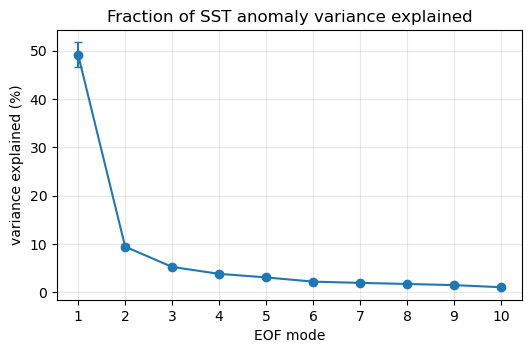

In [12]:
n_modes = 10
variance_fraction = solver.varianceFraction(neigs=n_modes) * 100
north_errors = solver.northTest(neigs=n_modes, vfscaled=True) * 100

fig, ax = plt.subplots(figsize=(6, 3.5))
ax.errorbar(np.arange(1, n_modes + 1), variance_fraction, yerr=north_errors, fmt='o-', capsize=3)
ax.set_xlabel('EOF mode')
ax.set_ylabel('variance explained (%)')
ax.set_xticks(np.arange(1, n_modes + 1))
ax.grid(alpha=0.3)
ax.set_title('Fraction of SST anomaly variance explained');

for k in range(3):
    print(f'EOF{k+1}: {variance_fraction[k].item():.1f} ± {north_errors[k].item():.1f} %')

Now get the first three EOFs and PCs. With `pcscaling=1` the PCs have unit variance, and `eofsAsCovariance` then gives each EOF in the units of the data (°C): it is the SST anomaly that goes with a one-standard-deviation value of the PC. These patterns are easier to interpret than the dimensionless eigenvectors.

The sign of an EOF and its PC is arbitrary: flipping both gives the same product. We fix the signs so that EOF1 is positive on average in the Niño 3.4 region (5°S–5°N, 170°W–120°W, i.e. 190°–240° in 0°–360° longitude), and EOF2 is positive on average in the far eastern equatorial Pacific (east of 240°).

In [13]:
n = 3
eofs = solver.eofsAsCovariance(neofs=n, pcscaling=1)
pcs = solver.pcs(npcs=n, pcscaling=1)

nino34_region = dict(yt_ocean=slice(-5, 5), xt_ocean=slice(190, 240))
far_east_region = dict(yt_ocean=slice(-5, 5), xt_ocean=slice(240, 280))

for k, region in [(0, nino34_region), (1, far_east_region)]:
    if eofs.sel(mode=k, **region).mean() < 0:
        eofs[k] = -eofs[k]
        pcs[:, k] = -pcs[:, k]

## Plot the EOF patterns

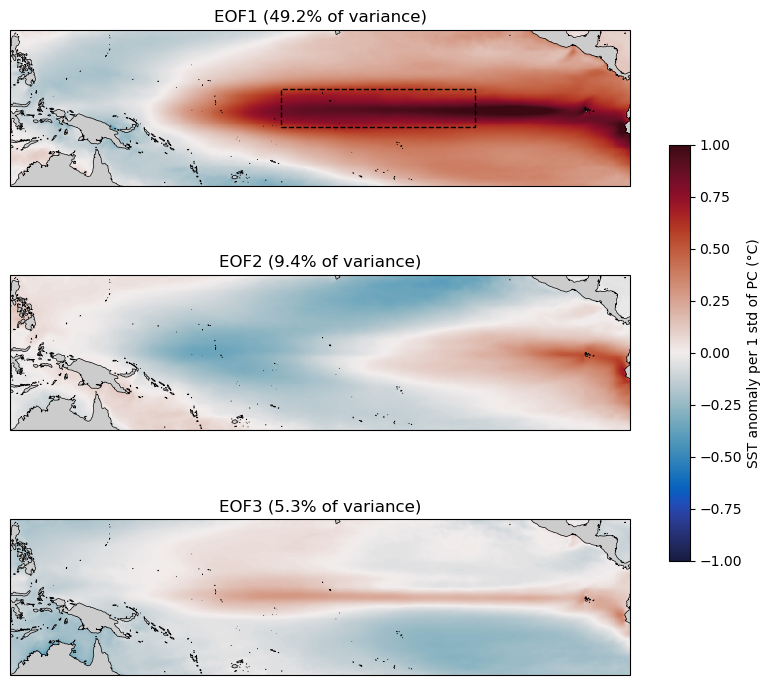

In [14]:
fig, axes = plt.subplots(n, 1, figsize=(10, 9), subplot_kw={'projection': ccrs.PlateCarree(central_longitude=180)})

for k, ax in enumerate(axes):
    p = eofs.sel(mode=k).plot(
        ax=ax, transform=ccrs.PlateCarree(), cmap=cmo.balance, vmin=-1, vmax=1,
        add_colorbar=False,
    )
    ax.add_feature(cft.LAND, color='0.8')
    ax.coastlines(linewidth=0.5)
    ax.set_title(f'EOF{k+1} ({variance_fraction[k].item():.1f}% of variance)')

# outline the Niño 3.4 region on EOF1
axes[0].plot([190, 240, 240, 190, 190], [-5, -5, 5, 5, -5], 'k--', linewidth=1, transform=ccrs.PlateCarree())

fig.colorbar(p, ax=axes, shrink=0.6, label='SST anomaly per 1 std of PC (°C)');

- **EOF1** is the ENSO pattern: warming along the equatorial cold tongue, strongest in the central and eastern Pacific, with weak cooling in the far western Pacific and the subtropics. It explains about half of the variance, far more than any other mode.
- **EOF2** has the opposite sign in the far eastern Pacific (warm) and the central Pacific (cool). Its time series below shows what it does.
- **EOF3** is a narrow equatorial band; it adds detail to how the cold tongue changes during and after events.

## Plot the principal components

We plot against decimal year and shade three strong El Niño events (1982–83, 1997–98 and 2015–16).

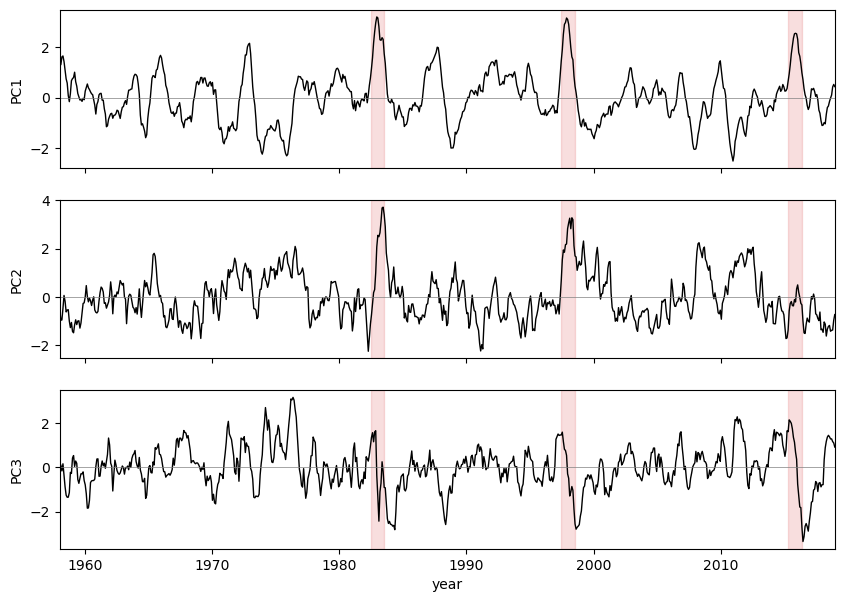

In [15]:
decimal_year = pcs.time.dt.year + (pcs.time.dt.month - 0.5) / 12

fig, axes = plt.subplots(n, 1, figsize=(10, 7), sharex=True)

for k, ax in enumerate(axes):
    ax.plot(decimal_year, pcs.sel(mode=k), color='k', linewidth=1)
    ax.axhline(0, color='0.5', linewidth=0.5)
    ax.set_ylabel(f'PC{k+1}')
    for start, end in [(1982.5, 1983.5), (1997.4, 1998.5), (2015.3, 2016.4)]:
        ax.axvspan(start, end, color='tab:red', alpha=0.15)

axes[-1].set_xlabel('year')
axes[-1].set_xlim(decimal_year[0], decimal_year[-1]);

Positive peaks of PC1 are El Niño events and negative peaks La Niña events.

PC2 has large positive peaks only during the two strongest El Niños, 1982–83 and 1997–98, when the warming reached all the way to the South American coast. During the 2015–16 El Niño, whose warming was centred further west, PC2 is mostly negative. A single pattern (EOF1) cannot describe both kinds of event, so EOF2 corrects it: adding a positive EOF2 to EOF1 moves the warming east.

## Is EOF1 ENSO? Compare with the Niño 3.4 index

Whenever you interpret an EOF it's worth checking it against something independent. Here we compare PC1 with the Niño 3.4 index: the area-averaged SST anomaly over the Niño 3.4 region, smoothed with a 3-month running mean.

Correlation between PC1 and the Niño 3.4 index: 0.97


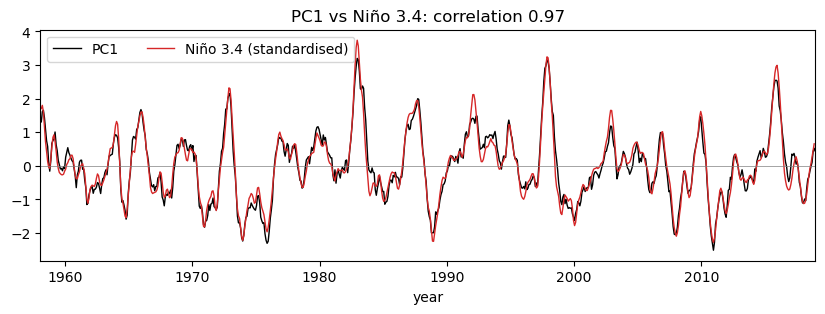

In [16]:
nino34 = sst_anom.sel(**nino34_region).weighted(area.sel(**nino34_region)).mean(['yt_ocean', 'xt_ocean'])
nino34 = nino34.rolling(time=3, center=True).mean()

r = xr.corr(pcs.sel(mode=0), nino34).item()
print(f'Correlation between PC1 and the Niño 3.4 index: {r:.2f}')

nino34_std = (nino34 - nino34.mean()) / nino34.std()

fig, ax = plt.subplots(figsize=(10, 3))
ax.plot(decimal_year, pcs.sel(mode=0), color='k', linewidth=1, label='PC1')
ax.plot(decimal_year, nino34_std, color='tab:red', linewidth=1, label='Niño 3.4 (standardised)')
ax.axhline(0, color='0.5', linewidth=0.5)
ax.set_xlim(decimal_year[0], decimal_year[-1])
ax.set_xlabel('year')
ax.legend(loc='upper left', ncol=2)
ax.set_title(f'PC1 vs Niño 3.4: correlation {r:.2f}');

PC1 follows the Niño 3.4 index almost exactly, so EOF1 is ENSO.

## Further reading

- Hannachi, A., Jolliffe, I. T., & Stephenson, D. B. (2007). Empirical orthogonal functions and related techniques in atmospheric science: A review. *International Journal of Climatology*, 27(9), 1119–1152. [doi:10.1002/joc.1499](https://doi.org/10.1002/joc.1499)
- The [`eofs` documentation](https://ajdawson.github.io/eofs/latest/) lists other things the solver can do, e.g. project new data onto the EOFs (`projectField`) or reconstruct the field from a few modes (`reconstructedField`).
- [`xeofs`](https://xeofs.readthedocs.io/) offers rotated EOFs, complex (Hilbert) EOFs, maximum covariance analysis and more.